# 에이전트 평가 세 전략

**이 노트북에서 할 일**

1. 에이전트가 질문에서 답까지 밟은 단계의 차례(궤적)를 모델 없이 메시지 목록으로 적고, 기준 궤적을 하나 정합니다.
2. 최종 답 평가·한 단계 평가·궤적 평가를 함수로 만들어, 궤적 넷을 같은 기준 궤적과 견줍니다.
3. 어느 평가가 어느 궤적을 거짓으로 보는지 확인하고, 답 글 하나만 바꿔 다시 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
궤적은 모두 코드로 적은 메시지 목록이라, 다시 실행해도 같은 값이 나와야 합니다.

읽는 파일은 같은 폴더의 도구 파일 `eval_tools.py` 하나이고, 쓰는 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
판은 agentevals 0.0.9와 langchain 1.4.0입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2·3절을 읽습니다.
궤적을 적는 방법과, 세 평가가 궤적의 어느 자리를 보는지 다루는 자리입니다.
4~6절은 궤적을 바꿔 가며 견주는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch29-agent-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 기준 궤적 메시지 여섯이라는 칸 안에 초록 상자 넷이 화살표로 이어집니다. 질문 HumanMessage, 첫 모델 응답 도구 요청 search_documents, 도구 결과와 둘째 응답 도구 요청 check_source와 도구 결과, 마지막 모델 응답 최종 답 글입니다. 칸 위의 파란 상자 궤적 평가 strict 모드 평가 함수에서 칸 전체로 점선 화살표가 갑니다. 칸 오른쪽 파란 상자 둘에서도 점선 화살표가 나갑니다. 한 단계 평가 first_step_pass는 첫 모델 응답 상자로, 최종 답 평가 final_answer_pass는 마지막 모델 응답 상자로 가는 그림](attachment:01-1-세-평가가-보는-자리.png)

칸 안의 화살표를 따라 위에서 아래로 읽습니다.
칸 안 초록 상자 넷은 노트북 2절에서 코드로 적은 기준 궤적이고, 셋째 상자에는 메시지 셋이 들어 있습니다.
칸 위의 파란 상자와 칸 오른쪽의 파란 상자 둘은 3절에서 정의하거나 만든 평가 함수입니다.
점선 화살표는 평가마다 보는 자리를 가리키고, 칸 위 궤적 평가의 점선만 칸 전체로 갑니다.
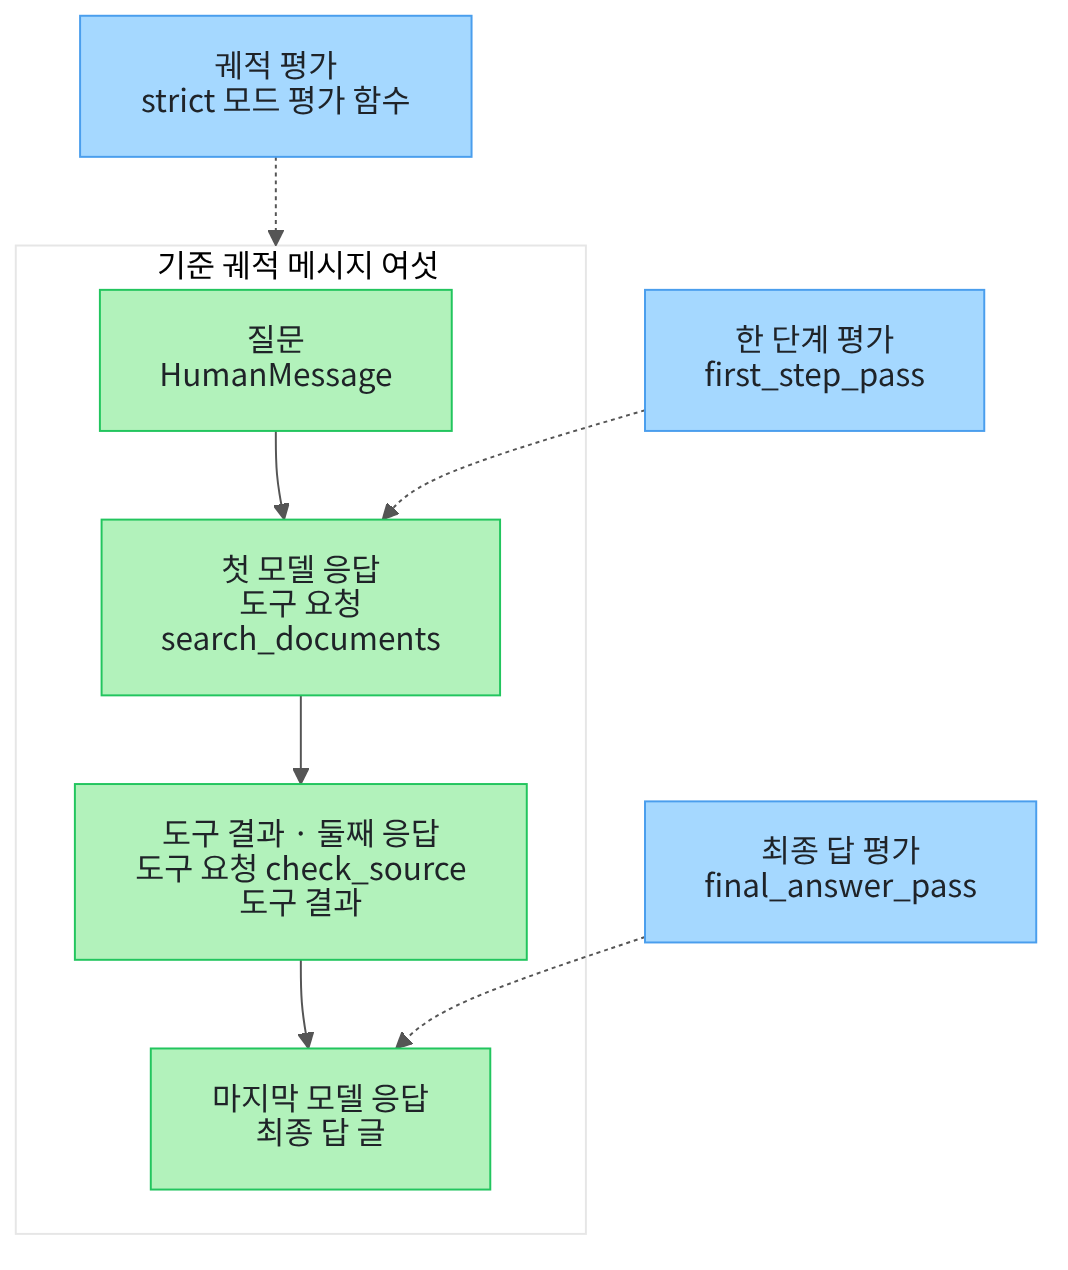

## 1. 준비

에이전트는 답을 내기 전에 도구를 고르고 부르는 일을 여러 번 합니다.
이 절은 그 과정을 평가하는 방법 세 가지를 견줍니다.
뜻과 구성은 본문 「핵심 개념」에서 풉니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "agentevals==0.0.9" "langchain==1.4.0"
from importlib.metadata import version

print("agentevals:", version("agentevals"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.


agentevals: 0.0.9
langchain: 1.4.0


**결과 읽기** — 출력 줄 `agentevals: 0.0.9`와 `langchain: 1.4.0`이 보입니다.
둘 다 실습 폴더 잠금과 같은 판입니다.
패키지 agentevals는 에이전트의 궤적을 평가하는 함수를 모은 라이브러리입니다.
패키지 langchain에서는 메시지 클래스 셋을 가져옵니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
함수 `create_trajectory_match_evaluator`는 궤적을 맞춰 보는 평가 함수를 만들어 내놓는 함수이고, 3절에서 씁니다.
메시지 클래스 셋은 Ch 13 04절·Ch 19 05절에서 쓴 `HumanMessage`·`AIMessage`·`ToolMessage`입니다.

In [2]:
# 궤적을 맞춰 보는 평가 함수를 만드는 함수와, 메시지 클래스 셋(Ch 13 04절·Ch 19 05절)을 가져옵니다
from agentevals.trajectory.match import create_trajectory_match_evaluator
from langchain.messages import AIMessage, HumanMessage, ToolMessage
# 앞 챕터에서 배운 함수 둘은 도구 파일에서 가져옵니다(Ch 19 04절·06절)
from eval_tools import show_messages, tool_call_names

print("도구 파일에서 가져온 함수:", "show_messages, tool_call_names")

도구 파일에서 가져온 함수: show_messages, tool_call_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: show_messages, tool_call_names`가 보입니다.
앞에서 배운 함수는 `eval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.

노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

함수 `tool_call_names`는 Ch 19 04절에서 배운 함수로, 모델 응답 하나가 요청한 도구 이름을 목록으로 내놓습니다.
함수 `show_messages`는 Ch 19 06절에서 배운 함수로, 메시지 목록을 한 줄에 하나씩 출력합니다.
이 노트북에는 API 키를 확인하는 셀이 없습니다.
모델을 부르지 않기 때문입니다.

## 2. 기준 궤적 만들기

에이전트가 질문에서 최종 답까지 밟은 단계의 차례를 궤적(trajectory)이라고 부릅니다.
Ch 17 04절은 실행 기록의 단계를 차례대로 늘어놓은 것을 단계 차례(궤적)라고 불렀고, 이 챕터는 그 말을 이어 씁니다.
이 절은 에이전트를 실제로 돌리지 않고, 질문·도구 호출 요청·도구 결과·답이 오간 메시지 목록을 코드로 적어 궤적으로 씁니다.

다음 셀은 궤적에 들어갈 글을 정합니다.
질문과 기준 답, 그리고 도구 둘이 내놓을 결과 글입니다.
도구 `search_documents`는 자료실 문서를 찾는 도구이고, `check_source`는 찾은 문서가 실제로 있는지 확인하는 도구입니다.
두 도구의 함수는 만들지 않고, 결과 글만 정해 둡니다.

In [3]:
# 질문과 기준 답, 도구마다 돌아올 결과 글을 정합니다(교재용 글 — 검색 결과는 Ch 14 문서 LIB-001의 글)
question = "일반 도서는 며칠 동안 빌릴 수 있나요?"
reference_answer = "일반 도서는 14일 동안 빌릴 수 있습니다."
tool_results = {
    "search_documents": "[LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.",
    "check_source": "LIB-001 문서가 있습니다. 제목: 도서 대출 기간",
}
print("질문:", question)
print("기준 답:", reference_answer)
print("결과 글을 정한 도구:", list(tool_results))

질문: 일반 도서는 며칠 동안 빌릴 수 있나요?
기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.
결과 글을 정한 도구: ['search_documents', 'check_source']


**결과 읽기** — 출력 줄 `질문: 일반 도서는 며칠 동안 빌릴 수 있나요?`와 `기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`가 보입니다.
라벨 `결과 글을 정한 도구:` 뒤에는 `'search_documents'`와 `'check_source'`가 있습니다.

검색 결과 글은 Ch 14 문서 LIB-001의 글 앞에 문서 ID를 대괄호로 붙인 모양입니다.
도구 이름과 이 모양은 Ch 21 05절에서 만든 검색 도구를 빌렸습니다.

다음 셀은 질문·도구 요청 목록·결과 글·답 글을 받아 궤적을 만드는 함수를 정의합니다.
도구 요청 하나는 Ch 19 04절에서 본 칸 넷(`name`·`args`·`id`·`type`)을 가진 딕셔너리입니다.
요청마다 그 요청을 담은 모델 응답(`AIMessage`)과, 같은 호출 ID를 단 도구 메시지(`ToolMessage`)를 한 쌍씩 붙입니다.
Ch 20 01절에서 모델 없이 도구 호출 요청을 손으로 만든 것과 같은 방법입니다.

In [4]:
# 질문·도구 요청 목록·결과 글·답 글로, 질문에서 답까지의 메시지 목록(궤적)을 만들어 내놓습니다
def make_trajectory(question, calls, results, answer):
    messages = [HumanMessage(content=question)]
    # 도구 요청 하나마다, 그 요청을 담은 모델 응답과 같은 호출 ID의 도구 메시지를 한 쌍씩 붙입니다
    for call in calls:
        messages.append(AIMessage(content="", tool_calls=[call]))
        messages.append(ToolMessage(content=results[call["name"]], tool_call_id=call["id"]))
    # 마지막에는 도구를 요청하지 않는 모델 응답, 곧 최종 답을 붙입니다
    messages.append(AIMessage(content=answer))
    return messages

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 요청이 둘이면 메시지는 질문 하나, 쌍 둘, 최종 답 하나로 모두 여섯 개가 됩니다.
도구 메시지의 글은 인자 `results`에서 도구 이름으로 찾습니다.

다음 셀은 기준 궤적을 만듭니다.
기준 궤적(reference trajectory)은 좋은 에이전트라면 밟을 것이라고 사람이 미리 적어 둔 궤적입니다.
이 절의 기준은 문서를 한 번 검색하고, 찾은 문서가 있는지 한 번 확인한 뒤 답하는 차례입니다.
이 차례는 흐름을 보여 주려고 이 절이 정한 예입니다.

In [5]:
# 기준 궤적의 도구 요청 둘을 정하고 궤적을 만듭니다(칸 넷은 Ch 19 04절 도구 호출 요청과 같은 모양)
search_args = {"query": "도서 대출 기간"}
source_args = {"doc_id": "LIB-001"}
reference_calls = [
    {"name": "search_documents", "args": search_args, "id": "call_1", "type": "tool_call"},
    {"name": "check_source", "args": source_args, "id": "call_2", "type": "tool_call"},
]
reference = make_trajectory(question, reference_calls, tool_results, reference_answer)
print("기준 궤적의 메시지 수:", len(reference))

기준 궤적의 메시지 수: 6


**결과 읽기** — 출력 줄 `기준 궤적의 메시지 수: 6`이 보입니다.
질문 하나, 도구 요청과 결과의 쌍 둘, 최종 답 하나입니다.
인자 딕셔너리 `search_args`와 `source_args`는 4절에서 다른 궤적을 만들 때 다시 씁니다.

다음 셀은 기준 궤적을 함수 `show_messages`로 한 줄씩 봅니다.
이 함수는 최종 답의 글을 출력하지 않으므로, 마지막 메시지의 글을 따로 출력합니다.
번호 `-1`은 Ch 16 03절의 음수 슬라이스처럼 뒤에서 센 자리이고, 목록의 마지막을 가리킵니다.

In [6]:
# 기준 궤적의 메시지를 차례대로 보고, 마지막 메시지의 글(최종 답)도 봅니다
print("기준 궤적:")
show_messages(reference)
# 번호 -1은 목록의 마지막 자리입니다
print("최종 답:", reference[-1].content)

기준 궤적:
HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
AIMessage | 도구 호출 요청: ['check_source']
ToolMessage | 결과 상태: success | 내용: LIB-001 문서가 있습니다. 제목: 도서 대출 기간
AIMessage | 도구 호출 요청: []
최종 답: 일반 도서는 14일 동안 빌릴 수 있습니다.


**결과 읽기** — 라벨 `기준 궤적:` 아래 여섯 줄이 메시지 여섯의 종류입니다.
둘째 줄 `AIMessage | 도구 호출 요청: ['search_documents']`가 첫 모델 응답이고, 넷째 줄이 `check_source`를 요청한 둘째 응답입니다.
도구 메시지 두 줄은 결과 상태가 `success`이고, 내용은 앞 셀에서 정한 결과 글입니다.
마지막 `AIMessage` 줄은 도구 호출 요청이 빈 목록 `[]`이고, 출력 줄 `최종 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`가 그 응답의 글입니다.

다음 셀은 궤적 전체에서 요청한 도구 이름을 차례대로 모으는 함수를 정의합니다.
모델 응답마다 함수 `tool_call_names`로 이름을 꺼내, 한 목록에 이어 붙입니다.

In [7]:
# 궤적의 모델 응답마다 요청한 도구 이름을 차례대로 모아, 목록 하나로 내놓습니다
def called_tool_names(messages):
    names = []
    for message in messages:
        # 도구 호출 요청은 모델 응답(AIMessage)에만 있습니다
        if type(message).__name__ == "AIMessage":
            for name in tool_call_names(message):
                names.append(name)
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
클래스 이름을 글로 꺼내는 `type(message).__name__`은 Ch 19 06절의 `show_messages`에도 있는 줄입니다.
질문과 도구 메시지는 건너뛰고 모델 응답만 봅니다.

다음 셀은 기준 궤적의 도구 차례와 도구 요청 수를 봅니다.

In [8]:
# 기준 궤적의 도구 차례와 도구 요청 수를 봅니다
reference_names = called_tool_names(reference)
print("기준 궤적의 도구 차례:", reference_names)
print("도구 요청 수:", len(reference_names))

기준 궤적의 도구 차례: ['search_documents', 'check_source']
도구 요청 수: 2


**결과 읽기** — 출력 줄 `기준 궤적의 도구 차례: ['search_documents', 'check_source']`와 `도구 요청 수: 2`가 보입니다.
기준 궤적은 검색 한 번, 출처 확인 한 번으로 도구를 두 번 요청합니다.
이 목록은 도구 이름만 모은 도구 차례이고, 궤적은 도구 결과와 답까지 든 메시지 목록 전체입니다.

## 3. 세 평가 함수

LangSmith 문서는 에이전트를 평가하는 방법을 셋으로 나눕니다.
마지막 답만 보는 최종 답 평가, 한 단계만 떼어 보는 한 단계 평가, 모든 단계를 보는 궤적 평가입니다.
이 절은 셋을 함수 하나씩으로 적고, 세 함수 모두 실제 궤적과 기준 궤적을 인자로 받게 합니다.

다음 셀은 최종 답 평가(final response)를 정의합니다.
마지막 메시지의 글이 기준 궤적의 마지막 글과 글자까지 같으면 `True`를 내놓습니다.
Ch 18 05절의 코드 검사처럼, 모델을 부르지 않고 코드 규칙으로 판정합니다.

In [9]:
# 최종 답 평가: 마지막 메시지의 글이 기준 궤적의 마지막 글과 글자까지 같은지 봅니다
def final_answer_pass(messages, reference):
    actual_text = messages[-1].content
    expected_text = reference[-1].content
    return actual_text == expected_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
글자가 하나라도 다르면 `False`입니다.
뜻이 같은지까지는 보지 않으며, 이 한계는 6절에서 다시 봅니다.

다음 셀은 한 단계 평가(single step)를 정의합니다.
이 절에서 볼 한 단계는 첫 모델 응답이고, 메시지 목록의 1번 자리에 있습니다.
그 응답이 요청한 도구 이름 목록이 기준 궤적의 첫 응답과 같으면 `True`를 내놓습니다.

In [10]:
# 한 단계 평가: 첫 모델 응답(메시지 목록의 1번 자리)이 요청한 도구 이름이 기준과 같은지 봅니다
def first_step_pass(messages, reference):
    actual_names = tool_call_names(messages[1])
    expected_names = tool_call_names(reference[1])
    return actual_names == expected_names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
첫 응답 뒤의 단계는 이 함수가 보지 않습니다.
LangSmith 문서도 한 단계 평가는 빠르지만, 에이전트 전체가 아니라 한 단계만 본다고 적습니다.

다음 셀은 궤적 평가(trajectory)에 쓸 평가 함수를 라이브러리로 만듭니다.
함수 `create_trajectory_match_evaluator`는 실제 궤적을 기준 궤적과 코드 규칙으로 맞춰 보는 평가 함수를 만들어 내놓습니다.
이 챕터는 이렇게 맞춰 보는 방법을 궤적 맞춰 보기(trajectory match)라고 부릅니다.

맞춰 보는 규칙(모드)은 인자 `trajectory_match_mode`로 고르고, 이 절은 `"strict"` 하나만 씁니다.
모드 `strict`는 메시지 수와 차례, 도구 요청의 이름과 인자가 기준과 모두 같아야 참을 냅니다.
모드는 셋이 더 있고, 02절에서 넷을 견줍니다.

In [11]:
# 궤적을 맞춰 보는 평가 함수를 strict 모드로 만듭니다(모드 이름을 넣으면 평가 함수를 내놓습니다)
strict_match = create_trajectory_match_evaluator(trajectory_match_mode="strict")
# 평가 함수에 실제 궤적(outputs)과 기준 궤적(reference_outputs)을 넣으면 결과 딕셔너리를 내놓습니다
self_result = strict_match(outputs=reference, reference_outputs=reference)
print("평가 함수의 종류:", type(strict_match).__name__)
print("결과 딕셔너리:", self_result)

평가 함수의 종류: function
결과 딕셔너리: {'key': 'trajectory_strict_match', 'score': True, 'comment': None, 'metadata': None}


**결과 읽기** — 출력 줄 `평가 함수의 종류: function`이 보입니다.
만든 평가 함수는 평범한 파이썬 함수처럼 부를 수 있습니다.
라벨 `결과 딕셔너리:` 뒤에 `'key': 'trajectory_strict_match'`와 `'score': True`가 있습니다.
칸 `score`가 판정이고, 기준 궤적을 자기 자신과 견줬으니 참입니다.

칸 `comment`와 `metadata`는 `None`입니다.
LangChain 문서의 예시 결과에는 칸 셋만 있고, 설치판 출력에는 칸 `metadata`가 더 있습니다.
이 절은 칸 `score`만 꺼내 씁니다.

다음 셀은 이 평가 함수로 궤적 평가를 하는 함수를 정의합니다.

In [12]:
# 궤적 평가: 평가 함수로 실제 궤적을 기준 궤적과 견주고, 결과 딕셔너리의 칸 score만 꺼냅니다
def trajectory_pass(messages, reference, evaluator):
    result = evaluator(outputs=messages, reference_outputs=reference)
    return result["score"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
평가 함수를 인자 `evaluator`로 받아, 다른 모드로 만든 평가 함수도 넘길 수 있게 했습니다.

다음 셀은 세 평가를 한 궤적에 모두 적용하는 함수를 정의합니다.
결과는 Ch 17 01절처럼 한국어 키 딕셔너리 한 줄입니다.

In [13]:
# 세 평가를 한 궤적에 모두 적용해, 한국어 키 딕셔너리 한 줄로 내놓습니다
def three_results(messages, reference, evaluator):
    row = {
        "최종 답": final_answer_pass(messages, reference),
        "한 단계": first_step_pass(messages, reference),
        "궤적": trajectory_pass(messages, reference, evaluator),
    }
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
키 셋은 `최종 답`·`한 단계`·`궤적`이고, 값은 모두 참·거짓 값입니다.

## 4. 견줄 궤적 넷 만들기

이제 기준 궤적과 견줄 실제 궤적 넷을 만듭니다.
모두 코드로 적은 궤적이고, 실제 에이전트가 만든 궤적은 03절에서 봅니다.
첫째는 기준 궤적과 같은 요청·답으로 만든 궤적입니다.
나머지 셋과 견줄 때, 모든 평가가 참인 줄이 되는지 봅니다.

In [14]:
# 기준 궤적과 같은 요청·답으로 실제 궤적을 하나 새로 만듭니다(모든 평가가 참이어야 할 줄)
same = make_trajectory(question, reference_calls, tool_results, reference_answer)
same_names = called_tool_names(same)
print("도구 차례:", same_names)
print("최종 답:", same[-1].content)

도구 차례: ['search_documents', 'check_source']
최종 답: 일반 도서는 14일 동안 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `도구 차례: ['search_documents', 'check_source']`와 `최종 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`가 보입니다.
기준 궤적과 같은 요청·답으로 만든 새 목록입니다.

다음 셀은 검색을 세 번 한 궤적을 만듭니다.
같은 검색어로 문서를 세 번 찾은 뒤 출처를 확인하고, 답은 기준과 같은 글입니다.
도구를 필요 없이 더 부른 낭비 장면입니다.

In [15]:
# 같은 검색어로 검색을 세 번 한 뒤 출처를 확인하는 궤적을 만듭니다(답은 기준과 같은 글)
wasteful_calls = [
    {"name": "search_documents", "args": search_args, "id": "call_1", "type": "tool_call"},
    {"name": "search_documents", "args": search_args, "id": "call_2", "type": "tool_call"},
    {"name": "search_documents", "args": search_args, "id": "call_3", "type": "tool_call"},
    {"name": "check_source", "args": source_args, "id": "call_4", "type": "tool_call"},
]
wasteful = make_trajectory(question, wasteful_calls, tool_results, reference_answer)
wasteful_names = called_tool_names(wasteful)
print("도구 차례:", wasteful_names)
print("도구 요청 수:", len(wasteful_names), "| 메시지 수:", len(wasteful))

도구 차례: ['search_documents', 'search_documents', 'search_documents', 'check_source']
도구 요청 수: 4 | 메시지 수: 10


**결과 읽기** — 라벨 `도구 차례:` 뒤에 `'search_documents'`가 셋, `'check_source'`가 하나 있습니다.
출력 줄 `도구 요청 수: 4 | 메시지 수: 10`으로, 기준 궤적보다 도구 요청이 둘, 메시지가 넷 늘었습니다.

다음 셀은 도구 요청은 기준과 같고 답 글만 틀린 궤적을 만듭니다.
답 글에는 14일이 아니라 7일이라고 적습니다.

In [16]:
# 도구 요청은 기준과 같고 답 글만 틀린 궤적을 만듭니다
wrong_text = "일반 도서는 7일 동안 빌릴 수 있습니다."
wrong_answer = make_trajectory(question, reference_calls, tool_results, wrong_text)
wrong_names = called_tool_names(wrong_answer)
print("도구 차례:", wrong_names)
print("최종 답:", wrong_answer[-1].content)

도구 차례: ['search_documents', 'check_source']
최종 답: 일반 도서는 7일 동안 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `도구 차례: ['search_documents', 'check_source']`는 기준 궤적과 같습니다.
출력 줄 `최종 답: 일반 도서는 7일 동안 빌릴 수 있습니다.`는 기준 답과 다릅니다.
도구를 바르게 부르고도 답을 틀리게 쓴 장면입니다.

다음 셀은 도구 차례를 바꾼 궤적을 만듭니다.
출처 확인을 먼저 하고 검색을 뒤에 하며, 답은 기준과 같은 글입니다.

In [17]:
# 출처 확인을 먼저 하고 검색을 뒤에 하는, 차례를 바꾼 궤적을 만듭니다(답은 기준과 같은 글)
reversed_calls = [
    {"name": "check_source", "args": source_args, "id": "call_1", "type": "tool_call"},
    {"name": "search_documents", "args": search_args, "id": "call_2", "type": "tool_call"},
]
reversed_order = make_trajectory(question, reversed_calls, tool_results, reference_answer)
reversed_names = called_tool_names(reversed_order)
print("도구 차례:", reversed_names)

도구 차례: ['check_source', 'search_documents']


**결과 읽기** — 출력 줄 `도구 차례: ['check_source', 'search_documents']`가 보입니다.
도구 둘은 기준 궤적과 같고, 차례만 거꾸로입니다.

## 5. 세 평가로 궤적 넷 견주기

다음 셀은 궤적 넷을 이름과 함께 딕셔너리에 모으고, 궤적마다 세 평가 결과를 한 줄씩 출력합니다.
네 궤적 모두 같은 기준 궤적, 같은 평가 함수와 견줍니다.
실행 전에 예상해 봅니다.
어느 궤적에서 어느 평가가 거짓을 낼까요?

In [18]:
# 궤적 넷을 이름과 함께 모으고, 궤적마다 세 평가 결과를 한 줄씩 출력합니다
trajectories = {"기준과 같음": same, "검색 세 번": wasteful, "답만 틀림": wrong_answer, "차례 바꿈": reversed_order}
print("궤적 | 최종 답 평가 | 한 단계 평가 | 궤적 평가")
for name in trajectories:
    row = three_results(trajectories[name], reference, strict_match)
    print(name, "|", row["최종 답"], "|", row["한 단계"], "|", row["궤적"])

궤적 | 최종 답 평가 | 한 단계 평가 | 궤적 평가
기준과 같음 | True | True | True
검색 세 번 | True | True | False
답만 틀림 | False | True | True
차례 바꿈 | True | False | False


**결과 읽기** — 줄 `기준과 같음 | True | True | True`는 세 평가가 모두 참입니다.
줄 `검색 세 번 | True | True | False`에서는 궤적 평가만 거짓입니다.
줄 `답만 틀림 | False | True | True`에서는 최종 답 평가만 거짓입니다.
줄 `차례 바꿈 | True | False | False`에서는 한 단계 평가와 궤적 평가가 거짓입니다.

세 평가가 거짓을 낸 궤적이 서로 다릅니다.
답만 보는 평가는 낭비와 차례를 보지 못했고, 차례를 보는 평가는 틀린 답을 보지 못했습니다.

다음 셀은 이 결과를 궤적 쪽에서 다시 읽습니다.
궤적마다 거짓을 낸 평가의 이름만 모읍니다.

In [19]:
# 궤적마다 거짓(False)을 낸 평가의 이름만 모아 출력합니다
for name in trajectories:
    row = three_results(trajectories[name], reference, strict_match)
    failed = []
    for strategy in row:
        if not row[strategy]:
            failed.append(strategy)
    print(name, "| 거짓을 낸 평가:", failed)

기준과 같음 | 거짓을 낸 평가: []
검색 세 번 | 거짓을 낸 평가: ['궤적']
답만 틀림 | 거짓을 낸 평가: ['최종 답']
차례 바꿈 | 거짓을 낸 평가: ['한 단계', '궤적']


**결과 읽기** — 줄 `검색 세 번 | 거짓을 낸 평가: ['궤적']`과 `답만 틀림 | 거짓을 낸 평가: ['최종 답']`이 보입니다.
이 두 궤적은 평가 하나만 문제를 찾았습니다.
그 평가를 빼면 두 궤적의 문제는 판정에 드러나지 않습니다.
줄 `차례 바꿈 | 거짓을 낸 평가: ['한 단계', '궤적']`에서는 두 평가가 함께 찾았습니다.

다음 셀은 한 단계 평가가 본 자리, 곧 궤적마다 첫 모델 응답의 도구 요청만 꺼내 봅니다.
메시지 목록의 1번 자리가 첫 모델 응답입니다.

In [20]:
# 궤적 넷의 첫 모델 응답(1번 자리)이 요청한 도구 이름만 봅니다(한 단계 평가가 보는 자리)
for name in trajectories:
    first_names = tool_call_names(trajectories[name][1])
    print(name, "| 첫 응답의 도구 요청:", first_names)

기준과 같음 | 첫 응답의 도구 요청: ['search_documents']
검색 세 번 | 첫 응답의 도구 요청: ['search_documents']
답만 틀림 | 첫 응답의 도구 요청: ['search_documents']
차례 바꿈 | 첫 응답의 도구 요청: ['check_source']


**결과 읽기** — 줄 `차례 바꿈 | 첫 응답의 도구 요청: ['check_source']`만 기준과 다르고, 나머지 세 줄은 `['search_documents']`입니다.
검색 세 번 궤적도 첫 응답은 기준과 같아, 한 단계 평가는 참을 냈습니다.
낭비는 둘째·셋째 응답에서 일어났고, 이 함수는 그 자리를 보지 않습니다.

이 네 궤적에서는 한 단계 평가가 거짓이면 궤적 평가도 거짓이었습니다.
모드 `strict`는 첫 응답의 도구 요청까지 기준과 견주기 때문입니다.
대신 한 단계 평가는 문제가 난 자리가 첫 응답이라는 것을 짚어 줍니다.

다음 셀은 답만 틀린 궤적을 기준 궤적과 견줘, 궤적 평가가 왜 참을 냈는지 봅니다.
메시지 수, 도구 차례, 최종 답을 차례로 견줍니다.

In [21]:
# 답만 틀린 궤적을 기준 궤적과 견줘, 무엇이 같고 무엇이 다른지 봅니다
print("메시지 수가 같은가:", len(wrong_answer) == len(reference))
print("도구 차례가 같은가:", wrong_names == reference_names)
print("최종 답이 같은가:", wrong_answer[-1].content == reference[-1].content)

메시지 수가 같은가: True
도구 차례가 같은가: True
최종 답이 같은가: False


**결과 읽기** — 출력 줄 `메시지 수가 같은가: True`와 `도구 차례가 같은가: True`, `최종 답이 같은가: False`가 보입니다.
두 궤적은 마지막 메시지의 글만 다릅니다.
모드 `strict`는 메시지 수와 역할, 도구 요청을 견주고, 메시지 글은 견주지 않습니다.
그래서 틀린 답을 쓴 궤적도 궤적 평가를 통과했습니다.

설치판 agentevals 0.0.9 소스 `trajectory/strict.py` 20~76행에도 메시지 글을 견주는 줄이 없습니다.
LangChain 문서도 이 모드에서 메시지 글은 달라도 된다고 적습니다.

## 6. 값 바꿔 보기: 답 글 하나만 바꾸기

값 하나만 바꿔 봅니다.
바꿀 값은 답만 틀린 궤적의 답 글이고, 뜻이 맞는 다른 글 「14일 동안 빌릴 수 있습니다.」를 넣습니다.
도구 요청 목록은 그대로 둡니다.
실행 전에 예상해 봅니다.
답이 맞게 바뀌었으니 최종 답 평가는 참이 될까요?

In [22]:
# 값 바꿔 보기: 답만 틀린 궤적에서 답 글 하나만, 뜻이 맞는 다른 글로 바꾼 궤적을 만듭니다
reworded_text = "14일 동안 빌릴 수 있습니다."
reworded = make_trajectory(question, reference_calls, tool_results, reworded_text)
print("기준 답:", reference[-1].content)
print("바꾼 답:", reworded[-1].content)

기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.
바꾼 답: 14일 동안 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`와 `바꾼 답: 14일 동안 빌릴 수 있습니다.`가 보입니다.
뜻은 같지만 앞의 「일반 도서는」이 빠져 글자가 다릅니다.

다음 셀은 바꾼 궤적과 답만 틀린 궤적의 세 평가 결과를 나란히 봅니다.

In [23]:
# 답만 틀린 궤적과 답 글을 바꾼 궤적의 세 평가 결과를 나란히 봅니다
wrong_row = three_results(wrong_answer, reference, strict_match)
reworded_row = three_results(reworded, reference, strict_match)
print("답만 틀림:", wrong_row)
print("답 글을 바꿈:", reworded_row)
print("두 줄이 같은가:", wrong_row == reworded_row)

답만 틀림: {'최종 답': False, '한 단계': True, '궤적': True}
답 글을 바꿈: {'최종 답': False, '한 단계': True, '궤적': True}
두 줄이 같은가: True


**결과 읽기** — 라벨 `답 글을 바꿈:` 뒤 딕셔너리에서도 `'최종 답': False`입니다.
출력 줄 `두 줄이 같은가: True`로, 답이 틀린 궤적과 뜻이 맞는 궤적의 세 판정이 같았습니다.
최종 답 평가는 글자로 견줘서, 틀린 답과 말만 다른 맞는 답을 가르지 못했습니다.
나머지 두 평가는 답 글을 보지 않아 두 궤적 모두 참입니다.

뜻이 같은지 보려면 코드 규칙 대신 글을 읽고 판정하는 쪽이 필요합니다.
Ch 15 01절의 평가 모델(judge)이 그런 쪽이고, 03절에서 궤적을 평가 모델로 판정합니다.

## 정리

1. 같은 기준 궤적과 견줘도, 검색 세 번은 궤적 평가만, 답만 틀림은 최종 답 평가만 거짓을 냈습니다.
2. 차례 바꿈은 한 단계 평가와 궤적 평가가 함께 거짓을 냈고, 한 단계 평가는 문제가 첫 응답에 있음을 짚었습니다.
3. 모드 `strict`는 메시지 글을 보지 않고, 글자로 견주는 최종 답 평가는 뜻이 같은 다른 글을 거짓으로 봤습니다.

02절에서는 모드 `strict` 말고 모드 셋을 더 보고, 네 모드가 차례와 빠진 요청·더한 요청을 어떻게 달리 보는지 견줍니다.